<a href="https://colab.research.google.com/github/manshikumarics24-hue/AI-lab/blob/main/week_10_alpha-beta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math

def alpha_beta(depth, node_index, is_max, leaves, alpha, beta, max_depth, b, pruned):
    # Base case: reached a leaf node
    if depth == max_depth:
        return leaves[node_index], [f"Leaf({leaves[node_index]})"]

    best_path = []

    if is_max:
        best_val = -math.inf
        for i in range(b):
            child_idx = node_index * b + i
            val, path = alpha_beta(
                depth + 1, child_idx, False, leaves, alpha, beta, max_depth, b, pruned
            )
            if val > best_val:
                best_val = val
                best_path = [f"MAX(d={depth}, n={node_index})"] + path

            alpha = max(alpha, best_val)

            # Beta cutoff: prune remaining siblings
            if alpha >= beta:
                for rem in range(i + 1, b):
                    rem_idx = node_index * b + rem
                    span = b ** (max_depth - (depth + 1))
                    skipped_leaves = leaves[rem_idx * span : (rem_idx + 1) * span]
                    pruned.append(
                        f"Depth {depth + 1}, Node {rem_idx} (leaves {skipped_leaves}) [alpha={alpha} >= beta={beta}]"
                    )
                break
        return best_val, best_path

    else:
        best_val = math.inf
        for i in range(b):
            child_idx = node_index * b + i
            val, path = alpha_beta(
                depth + 1, child_idx, True, leaves, alpha, beta, max_depth, b, pruned
            )
            if val < best_val:
                best_val = val
                best_path = [f"MIN(d={depth}, n={node_index})"] + path

            beta = min(beta, best_val)

            # Alpha cutoff: prune remaining siblings
            if alpha >= beta:
                for rem in range(i + 1, b):
                    rem_idx = node_index * b + rem
                    span = b ** (max_depth - (depth + 1))
                    skipped_leaves = leaves[rem_idx * span : (rem_idx + 1) * span]
                    pruned.append(
                        f"Depth {depth + 1}, Node {rem_idx} (leaves {skipped_leaves}) [alpha={alpha} >= beta={beta}]"
                    )
                break
        return best_val, best_path


def main():
    b = int(input("Enter branching factor (e.g., 2 for binary tree): "))
    leaves = list(map(int, input("Enter leaf node values separated by spaces: ").split()))
    mode = input("Start with MAX or MIN at root? (MAX/MIN): ").strip().upper()

    # Validate that the number of leaves forms a complete tree of branching factor b
    n = len(leaves)
    max_depth = round(math.log(n, b))
    if b ** max_depth != n:
        print(f"Error: Number of leaves ({n}) must be a power of the branching factor ({b}).")
        return

    is_max_root = (mode == "MAX")
    pruned_branches = []

    optimal_value, optimal_path = alpha_beta(
        depth=0,
        node_index=0,
        is_max=is_max_root,
        leaves=leaves,
        alpha=-math.inf,
        beta=math.inf,
        max_depth=max_depth,
        b=b,
        pruned=pruned_branches,
    )

    print("\n--- Results ---")
    print(f"Optimal Root Value : {optimal_value}")
    print(f"Path to Root       : {' -> '.join(optimal_path)}")
    print("Pruned Subtrees    :")
    if pruned_branches:
        for p in pruned_branches:
            print(f"  - {p}")
    else:
        print("  - None")


if __name__ == "__main__":
    main()

Enter branching factor (e.g., 2 for binary tree): 2
Enter leaf node values separated by spaces: 10 9 14 18 5 4 50 3
Start with MAX or MIN at root? (MAX/MIN): MAX

--- Results ---
Optimal Root Value : 10
Path to Root       : MAX(d=0, n=0) -> MIN(d=1, n=0) -> MAX(d=2, n=0) -> Leaf(10)
Pruned Subtrees    :
  - Depth 3, Node 3 (leaves [18]) [alpha=14 >= beta=10]
  - Depth 2, Node 3 (leaves [50, 3]) [alpha=10 >= beta=5]


Enter branching factor (e.g., 2): 2
Enter leaf node values separated by spaces: 10 9 14 18 5 4 50 3
Start with MAX or MIN at root? (MAX/MIN): MAX

Root Value: 10
Optimal Path: MAX(10) -> MIN(10) -> MAX(10) -> Leaf(10)
Diagram saved to: alpha_beta_solution.png


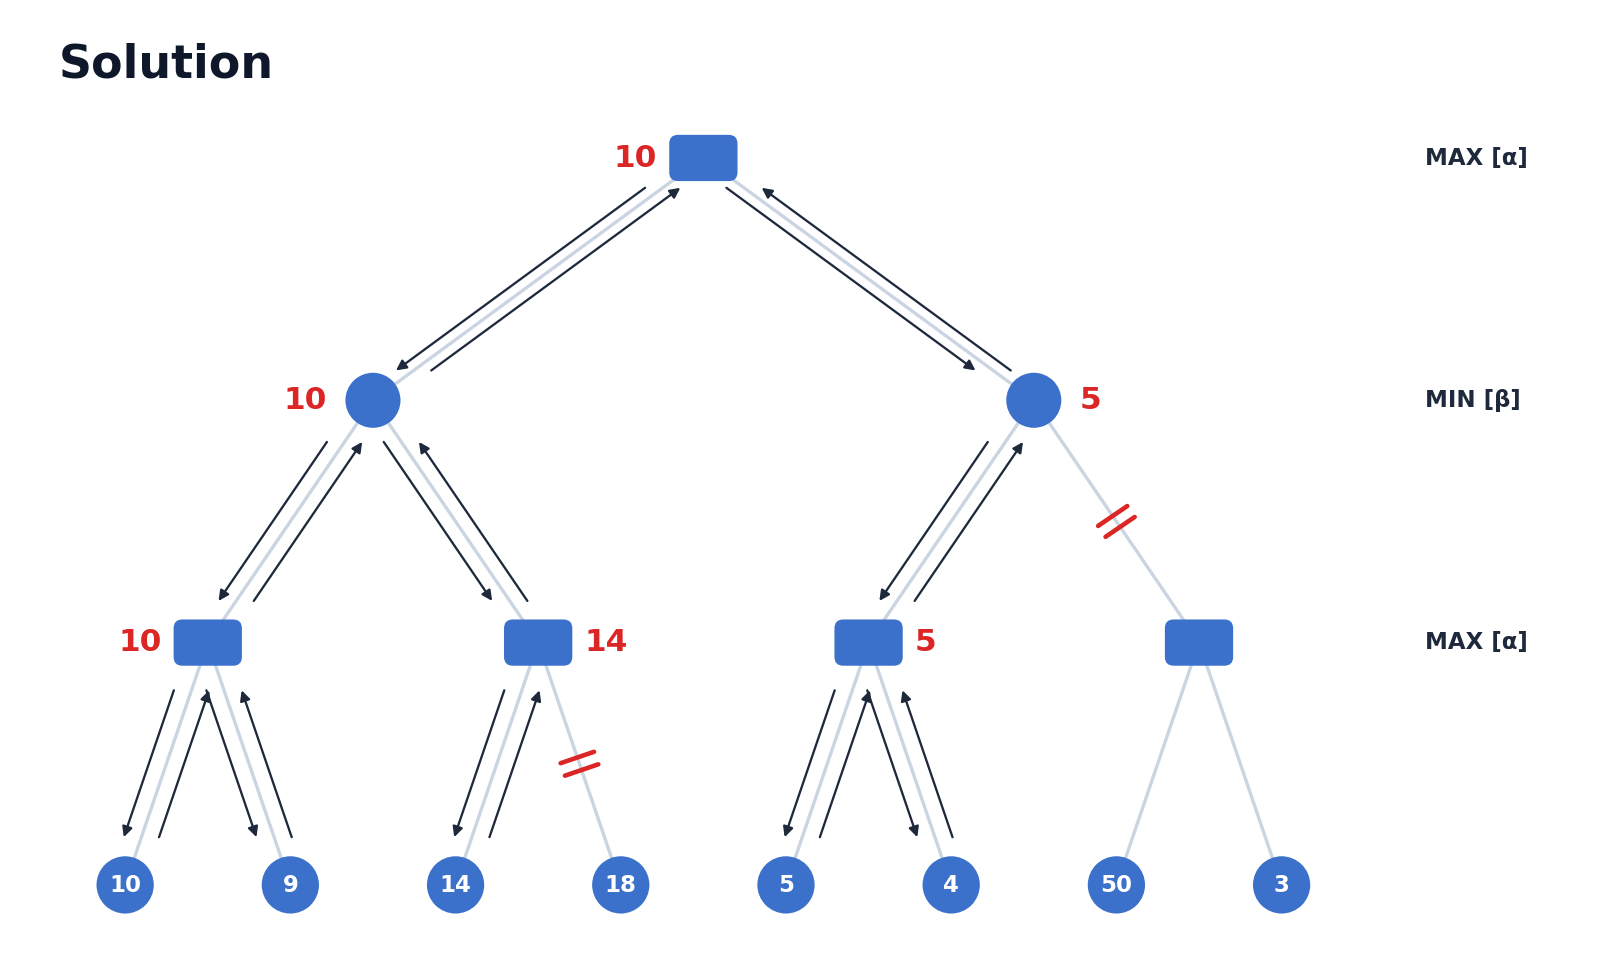

In [2]:
import math
import matplotlib.pyplot as plt
import matplotlib.patches as patches


def run_alpha_beta_with_trace(b, leaves, is_max_root):
    n = len(leaves)
    max_depth = round(math.log(n, b))

    node_values = {}
    visited_edges = set()
    pruned_edges = set()

    def dfs(depth, idx, is_max, alpha, beta):
        if depth == max_depth:
            return leaves[idx], [f"Leaf({leaves[idx]})"]

        best_path = []
        if is_max:
            best_val = -math.inf
            for i in range(b):
                c_idx = idx * b + i
                visited_edges.add(((depth, idx), (depth + 1, c_idx)))
                val, path = dfs(depth + 1, c_idx, False, alpha, beta)
                if val > best_val:
                    best_val = val
                    best_path = [f"MAX({val})"] + path
                alpha = max(alpha, best_val)
                if alpha >= beta:
                    for rem in range(i + 1, b):
                        rem_idx = idx * b + rem
                        pruned_edges.add(((depth, idx), (depth + 1, rem_idx)))
                    break
            node_values[(depth, idx)] = best_val
            return best_val, best_path
        else:
            best_val = math.inf
            for i in range(b):
                c_idx = idx * b + i
                visited_edges.add(((depth, idx), (depth + 1, c_idx)))
                val, path = dfs(depth + 1, c_idx, True, alpha, beta)
                if val < best_val:
                    best_val = val
                    best_path = [f"MIN({val})"] + path
                beta = min(beta, best_val)
                if alpha >= beta:
                    for rem in range(i + 1, b):
                        rem_idx = idx * b + rem
                        pruned_edges.add(((depth, idx), (depth + 1, rem_idx)))
                    break
            node_values[(depth, idx)] = best_val
            return best_val, best_path

    root_val, opt_path = dfs(0, 0, is_max_root, -math.inf, math.inf)
    return max_depth, root_val, opt_path, node_values, visited_edges, pruned_edges


def draw_alpha_beta_diagram(b, leaves, is_max_root, filename="alpha_beta_solution.png"):
    max_depth, root_val, opt_path, node_values, visited_edges, pruned_edges = (
        run_alpha_beta_with_trace(b, leaves, is_max_root)
    )

    n_leaves = len(leaves)
    fig_w = max(10, n_leaves * 1.35)
    fig_h = max(6.5, (max_depth + 1) * 2.0)
    fig, ax = plt.subplots(figsize=(fig_w, fig_h), dpi=150)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    # Compute node positions bottom-up
    coords = {}
    y_spacing = 2.2
    for idx in range(n_leaves):
        coords[(max_depth, idx)] = (idx * 1.5, 0.0)

    for d in range(max_depth - 1, -1, -1):
        y = (max_depth - d) * y_spacing
        for idx in range(b ** d):
            child_xs = [coords[(d + 1, idx * b + i)][0] for i in range(b)]
            coords[(d, idx)] = (sum(child_xs) / b, y)

    # 1. Draw tree edges, traversal arrows, and red '//' cutoff marks
    for d in range(max_depth):
        for idx in range(b ** d):
            x1, y1 = coords[(d, idx)]
            for i in range(b):
                c_idx = idx * b + i
                x2, y2 = coords[(d + 1, c_idx)]
                edge = ((d, idx), (d + 1, c_idx))

                ax.plot([x1, x2], [y1, y2], color="#CBD5E1", lw=1.6, zorder=1)

                dx, dy = x2 - x1, y2 - y1
                length = math.hypot(dx, dy)
                ux, uy = dx / length, dy / length
                nx, ny = -uy, ux

                if edge in visited_edges:
                    pad = 0.42
                    h_off = 0.16
                    # Downward exploration arrow (left of edge)
                    ax.annotate(
                        "",
                        xy=(x2 - ux * pad - h_off, y2 - uy * pad),
                        xytext=(x1 + ux * pad - h_off, y1 + uy * pad),
                        arrowprops=dict(arrowstyle="-|>", color="#1E293B", lw=1.1, mutation_scale=10),
                        zorder=2,
                    )
                    # Upward return arrow (right of edge)
                    ax.annotate(
                        "",
                        xy=(x1 + ux * pad + h_off, y1 + uy * pad),
                        xytext=(x2 - ux * pad + h_off, y2 - uy * pad),
                        arrowprops=dict(arrowstyle="-|>", color="#1E293B", lw=1.1, mutation_scale=10),
                        zorder=2,
                    )

                elif edge in pruned_edges:
                    mx, my = (x1 + x2) / 2, (y1 + y2) / 2
                    slash_len = 0.16
                    gap = 0.06
                    for shift in (-gap, gap):
                        cx, cy = mx + ux * shift, my + uy * shift
                        ax.plot(
                            [cx - nx * slash_len, cx + nx * slash_len],
                            [cy - ny * slash_len, cy + ny * slash_len],
                            color="#DC2626",
                            lw=2.2,
                            solid_capstyle="round",
                            zorder=4,
                        )

    # 2. Draw MAX squares, MIN circles, leaf circles, and red node values
    node_blue = "#3B71CA"
    for d in range(max_depth + 1):
        is_max = (d % 2 == 0) if is_max_root else (d % 2 == 1)
        for idx in range(b ** d):
            x, y = coords[(d, idx)]
            if d == max_depth:
                circ = patches.Circle((x, y), radius=0.26, facecolor=node_blue, edgecolor="none", zorder=3)
                ax.add_patch(circ)
                ax.text(
                    x, y, str(leaves[idx]), color="white", fontsize=11,
                    fontweight="bold", ha="center", va="center", zorder=4
                )
            else:
                if is_max:
                    w, h = 0.56, 0.36
                    rect = patches.FancyBboxPatch(
                        (x - w / 2, y - h / 2), w, h,
                        boxstyle="round,pad=0.03,rounding_size=0.08",
                        facecolor=node_blue, edgecolor="none", zorder=3
                    )
                    ax.add_patch(rect)
                else:
                    circ = patches.Circle((x, y), radius=0.25, facecolor=node_blue, edgecolor="none", zorder=3)
                    ax.add_patch(circ)

                if (d, idx) in node_values:
                    val = node_values[(d, idx)]
                    if idx == 0:
                        ax.text(
                            x - 0.42, y, str(val), color="#DC2626", fontsize=15,
                            fontweight="bold", ha="right", va="center", zorder=5
                        )
                    else:
                        ax.text(
                            x + 0.42, y, str(val), color="#DC2626", fontsize=15,
                            fontweight="bold", ha="left", va="center", zorder=5
                        )

    # 3. Right-side level labels (MAX [α] / MIN [β])
    right_x = (n_leaves - 1) * 1.5 + 1.3
    for d in range(max_depth):
        is_max = (d % 2 == 0) if is_max_root else (d % 2 == 1)
        y = (max_depth - d) * y_spacing
        label = "MAX [α]" if is_max else "MIN [β]"
        ax.text(
            right_x, y, label, color="#1E293B", fontsize=11,
            fontweight="semibold", ha="left", va="center"
        )

    ax.text(
        -0.6, max_depth * y_spacing + 0.85, "Solution",
        fontsize=22, fontweight="bold", color="#0F172A", ha="left", va="center"
    )

    ax.set_xlim(-1.0, right_x + 1.5)
    ax.set_ylim(-0.7, max_depth * y_spacing + 1.3)
    ax.set_aspect("equal")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(filename, bbox_inches="tight", dpi=150)
    print(f"\nRoot Value: {root_val}")
    print(f"Optimal Path: {' -> '.join(opt_path)}")
    print(f"Diagram saved to: {filename}")
    plt.show()


def main():
    b = int(input("Enter branching factor (e.g., 2): "))
    leaves = list(map(int, input("Enter leaf node values separated by spaces: ").split()))
    mode = input("Start with MAX or MIN at root? (MAX/MIN): ").strip().upper()

    n = len(leaves)
    max_depth = round(math.log(n, b))
    if b ** max_depth != n:
        print(f"Error: Number of leaves ({n}) must be a power of the branching factor ({b}).")
        return

    draw_alpha_beta_diagram(b, leaves, is_max_root=(mode == "MAX"))


if __name__ == "__main__":
    main()
